# 2026 DL Lab6: Image Generation with DDPM (U-Net)
**Student assignment / 學生作業版**

Implement the missing parts of a **time-conditioned U-Net** and train an
unconditional diffusion model on **Oxford Flowers102**.
本作業沿用引導式實作：閱讀每個 TODO 的步驟、輸入輸出與張量尺寸提示，
在 `Your Code Here` 與 `End of your code` 之間完成程式。

This notebook contains **8 implementation exercises**. Unfinished sections
intentionally raise `NotImplementedError`; replace each exception with your
implementation before running the corresponding section. 請勿只刪除例外而留白。
Checkpointing, EMA, mixed precision, preview images and ZIP export are supplied.

The final archive is **`student_outputs/DDPM/images.zip`**.
All saved cell outputs have been cleared; results must come from your own run.

Before we start, please put **your name** and **SID** in the following format:

Hi I'm 李俊彥, YOUR_STUDENT_ID.

**Your Answer:**

Hi I'm 王薪愷, 315832002.

## Overview
Train a **time-conditioned U-Net** to predict Gaussian noise added to real
**64×64 RGB** flower images. Both the U-Net and DiT versions use the same
**DDPM training objective**; the denoising backbone is different.

- **Training:** choose a timestep, add noise, predict that noise and minimize MSE.
- **Generation:** start from image-shaped Gaussian noise and iteratively denoise.
- **Output:** 8,189 generated PNG files inside one flat `images.zip` archive.
- **Evaluation:** submit your generated ZIP to Kaggle for **FID scoring (lower is better)**.
  FID compares sets of images; it is different from the training noise MSE.

Use basic PyTorch layers to complete the marked exercises. Do not replace
the exercises with a pretrained image generator or a ready-made denoising model.
We train from scratch; no pretrained generation weights are supplied.

References: [DDPM](https://arxiv.org/abs/2006.11239),
[DDIM](https://arxiv.org/abs/2010.02502),
[DiT](https://arxiv.org/abs/2212.09748).

## Implementation checklist
Follow the notebook in order and complete the eight numbered TODO blocks.
The style follows the guided Lab6 exercises: module definitions, interfaces
and operational scaffolding are given, while the core learning steps are missing.

| TODO | Exercise | Expected concept |
| --- | --- | --- |
| 1 | Data transformations | RGB image → normalized tensor |
| 2 | Time-conditioned residual block | Convolution, timestep injection and residual addition |
| 3 | U-Net encoder | Residual blocks and spatial downsampling |
| 4 | U-Net decoder | Skip-channel matching and spatial upsampling |
| 5 | Forward diffusion | Construct a noisy image at a chosen timestep |
| 6 | DDPM reverse step | Posterior mean, variance and the final-step boundary |
| 7 | Prepare a training batch | Random timesteps, Gaussian noise and noisy inputs |
| 8 | Noise-prediction loss | Denoiser prediction and scalar MSE |

Keep function signatures, tensor layouts and shared variable names unchanged.
Use the shape/formula checks before committing to a full training run.
A failed `NotImplementedError` identifies an unfinished exercise, not an
environment installation problem. Search for `raise NotImplementedError`
to find remaining implementation placeholders.

## 2026 submission and Kaggle competition
**2026 年競賽連結、截止時間、繳交平台與配分：由授課教師／助教另行公告。**
The previous year's invitation link and prediction/accuracy instructions do
not apply to this image-generation assignment. Kaggle ZIP/FID scoring must
be confirmed by the teaching staff before the competition is released.

Complete the TODO sections, record your experiments, and keep the notebook,
model configuration and training results. The generated-image contract is:

```text
images.zip
├── fake_00000.png
├── fake_00001.png
├── ...
└── fake_08188.png
```

Each image must be **64×64, RGB, 8-bit PNG**. There must be exactly **8,189**
images at the archive root, with no directories, JSON files or extra entries.
This notebook creates the archive at `student_outputs/DDPM/images.zip`.
Submit only the artifact requested by the final course announcement.

A validation pass checks the file format; it is not a quality score.
The official score must be recomputed from submitted images by the evaluator,
not obtained by accepting a student-entered `fid_score` value.

## Dataset and environment
You receive the course dataset and the two student notebooks. No additional
Python scripts are required to complete the notebooks and export your images.
Place the extracted **`resized_flowers102/`** folder and both notebooks in the
same project folder. The parent folder may have any name; the layout below
uses `your_project/` as an example.

```text
your_project/
├── resized_flowers102/           # provided 8,189 real images, 64×64 RGB
├── Lab7_DDPM_student.ipynb       # provided U-Net student notebook
├── Lab7_DiT_student.ipynb        # provided DiT student notebook
└── student_outputs/             # created automatically when the notebooks run
    ├── DDPM/                    # U-Net checkpoints, previews and images.zip
    └── DiT/                     # DiT checkpoints, previews and images.zip
```

The provided notebook filenames retain the legacy `Lab7` name; this assignment
is **Lab 6**. Follow the course's Lab6 naming rules when submitting your work.
If the dataset is supplied as a ZIP, extract it into `resized_flowers102/`
first. Keep the image files directly inside that folder, without an extra
nested dataset folder. Do not change the dataset files or split.

Start Jupyter/VS Code from the project folder or one of its child directories.
The configuration cell searches parent directories for `resized_flowers102/`
and creates the output folders automatically.

Select a Python kernel with **PyTorch, torchvision, Pillow, NumPy, Matplotlib,
tqdm and IPython** installed. Activating a terminal environment does not select
the notebook kernel. Full training is intended for a CUDA GPU; check that the
configuration cell prints `Device: cuda:0` when using a CUDA-enabled setup.

After you complete the TODOs and train the model, the supplied export function
creates `images.zip` and automatically checks the image count, filenames,
dimensions, RGB/PNG format and complete image decoding before finalizing it.
This is a file-format check, not an FID score. **No external validation script,
`pytorch-fid`, SciPy or Inception evaluation weights are required for training
and ZIP export.** Submit your best `images.zip` to Kaggle for FID scoring.
The notebook itself does not calculate a local FID score.


In [1]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import copy
import hashlib
import io
import json
import math
import random
import time
import zipfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
from IPython.display import FileLink, display

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.utils import make_grid, save_image

manualSeed = 0
random.seed(manualSeed)
np.random.seed(manualSeed)
torch.manual_seed(manualSeed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(manualSeed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

print("Random seed:", manualSeed)
print("PyTorch:", torch.__version__)


Random seed: 0
PyTorch: 2.7.1+cu118


In [2]:
# Start Jupyter in DL_Lab7 or a child directory.
def find_project_root():
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / "resized_flowers102").is_dir():
            return candidate
    raise FileNotFoundError(
        "Cannot find resized_flowers102/. Start Jupyter in DL_Lab7 or a child directory."
    )

project_root = find_project_root()
data_root = project_root / "resized_flowers102"
work_dir = project_root / "student_outputs" / "DDPM"
output_dir = work_dir / "outputs"
submission_path = work_dir / "images.zip"

# Data and model settings. The default model targets a single 12GB GPU.
workers = 2
batch_size = 32
image_size = 64
nc = 3
base_channels = 64
channel_multipliers = (1, 2, 4, 4)
dropout = 0.1

# Training settings. This is a starting budget, not a guaranteed FID target.
num_epochs = 400
lr = 2e-4
optimizer_betas = (0.9, 0.99)
weight_decay = 1e-4
warmup_epochs = 5
min_lr_ratio = 0.05
ema_decay = 0.9999
max_grad_norm = 1.0
use_amp = True
ngpu = 1
log_every = 50
preview_every = 10
checkpoint_every = 25

# Forward diffusion: the original 1,000-step linear beta schedule.
diffusion_steps = 1000
beta_start = 1e-4
beta_end = 0.02

# Checkpoints are saved at epoch boundaries, including optimizer and RNG state.
train_model = True
resume_checkpoint = None  # e.g. output_dir / "model_weight/last_checkpoint.pt"

# Both samplers are implemented. DDIM accelerates generation from the same DDPM.
sampling_method = "ddim"  # "ddpm" uses all diffusion_steps; "ddim" uses a subset.
sampling_steps = 250
ddim_eta = 0.0
sample_batch_size = 32
num_submission_images = 8189  # Keep the announced submission count for final export.
submission_seed = 12345
preview_count = 16
preview_sampling_steps = 50

device = torch.device("cuda:0" if torch.cuda.is_available() and ngpu > 0 else "cpu")
amp_enabled = bool(use_amp and device.type == "cuda")
if device.type == "cpu":
    print("CPU selected: use CPU for debugging; full training is intended for CUDA.")
print("Device:", device)
if device.type == "cuda":
    props = torch.cuda.get_device_properties(device)
    print("GPU:", props.name, "| CUDA memory: %.2f GiB" % (props.total_memory / 2**30))
print("Dataset:", data_root)
print("Final submission:", submission_path)


Device: cuda:0
GPU: Tesla V100-PCIE-32GB | CUDA memory: 31.74 GiB
Dataset: /root/DL/HW6/resized_flowers102
Final submission: /root/DL/HW6/student_outputs/DDPM/images.zip


## Load Flowers102 and define data transformations
The supplied `FlowerDataset` reads the existing flat image folder and returns
images directly, not `(image, label)` pairs. Labels are unused because this
assignment is **unconditional generation**. Dataset and DataLoader plumbing,
worker seeding and dataset fingerprinting are already provided.

**TODO 1 — Data transformations.** Implement a Compose pipeline that:

1. Applies a random horizontal flip with probability 0.5 during training.
2. Converts a PIL image to a floating-point tensor in `[0,1]`.
3. Normalizes all three RGB channels to `[-1,1]`.

The input images are already 64×64; resizing is unnecessary for this dataset.
Expected output per image: `torch.Tensor`, shape `(3,64,64)`.
Do not apply random augmentation to the evaluator's real-image reference.

We currently train on the entire supplied folder. This is not a held-out
test-set evaluation. The teaching staff will fix the reference set for FID;
FID alone does not prove that a model has not copied training images.

In [3]:
class FlowerDataset(Dataset):
    def __init__(self, root, transform=None, image_size=64):
        self.root = Path(root)
        self.files = sorted(
            p for p in self.root.iterdir()
            if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
        )
        if not self.files:
            raise FileNotFoundError("No images found in %s" % self.root)
        self.transform = transform
        self.image_size = image_size

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        with Image.open(self.files[index]) as image:
            if image.size != (self.image_size, self.image_size):
                raise ValueError("Expected %dx%d: %s" % (
                    self.image_size, self.image_size, self.files[index]))
            image = image.convert("RGB")
            return self.transform(image) if self.transform is not None else image.copy()

##############################################################################
# TODO 1: Define the data transformation pipeline.
# Input: a 64x64 RGB PIL image. Output: a (3,64,64) float tensor.
# Use transforms.Compose, random horizontal flipping (p=0.5),
# tensor conversion, and RGB normalization from [0,1] to [-1,1].
# Assign the completed pipeline to the variable transform.
##############################################################################
# Your Code Here
transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5),
    ),
])
# End of your code
##############################################################################

# Seed worker-side augmentation from the DataLoader's own reproducible generator.
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

dataset = FlowerDataset(data_root, transform=transform, image_size=image_size)
loader_generator = torch.Generator().manual_seed(manualSeed)
dataloader = DataLoader(
    dataset, batch_size=batch_size, shuffle=True, num_workers=workers,
    pin_memory=(device.type == "cuda"), drop_last=False,
    worker_init_fn=seed_worker, generator=loader_generator,
    persistent_workers=False,
)

# Record exact input contents so that resumed runs cannot silently change dataset.
dataset_hasher = hashlib.sha256()
for path in dataset.files:
    dataset_hasher.update(path.name.encode("utf-8"))
    dataset_hasher.update(hashlib.sha256(path.read_bytes()).digest())
dataset_sha256 = dataset_hasher.hexdigest()

print("訓練集樣本數量:", len(dataset))
print("Batches per epoch:", len(dataloader))
print("Planned optimizer updates:", len(dataloader) * num_epochs)


訓練集樣本數量: 8189
Batches per epoch: 256
Planned optimizer updates: 102400


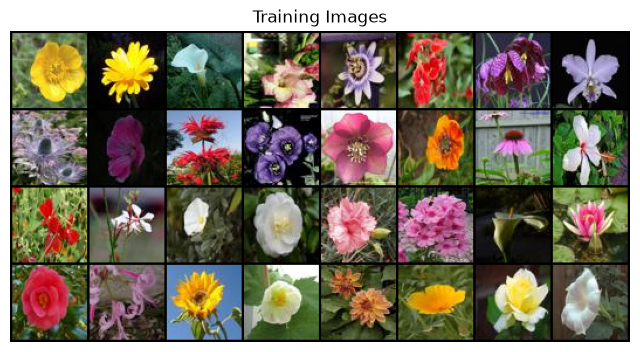

In [4]:
# The custom Dataset returns images directly, not (image, label).
real_batch = next(iter(dataloader))
plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Training Images")
plt.imshow(make_grid((real_batch[:64] + 1) / 2, nrow=8).permute(1, 2, 0).numpy())
plt.show()


## Build the time-conditioned U-Net
The model receives `x_t` of shape `(B,3,64,64)` and one timestep per image,
shape `(B,)`. It outputs predicted Gaussian noise of the same image shape.
The time embedding and bottleneck self-attention are supplied.

**TODO 2 — Residual block.** Follow the pre-activation sequence
`GroupNorm → SiLU → Conv`, inject the projected timestep by spatial
broadcasting, apply the second normalization/activation/dropout/convolution,
and add the shortcut. Use the modules already defined in `__init__`.

**TODO 3 / TODO 4 — Encoder and decoder.** Complete the two construction
loops. Each level contains two residual blocks. Encoder downsampling uses
a `4×4`, stride-2, padding-1 convolution; the final level keeps its size.
The decoder concatenates same-resolution skip features along channels,
then uses nearest-neighbor upsampling and a `3×3`, padding-1 convolution
to reach the next level. Update `current` so every block matches its input.

| Resolution | Channels after the level's residual blocks |
| --- | --- |
| 64×64 | 64 |
| 32×32 | 128 |
| 16×16 | 256 |
| 8×8 | 256 |

The supplied forward pass defines the skip-connection order. The decoder
visits these levels in reverse. The output layer has **no Tanh or Sigmoid**
because Gaussian noise is not restricted to an image's pixel range.

In [5]:
def group_norm(channels):
    return nn.GroupNorm(math.gcd(8, channels), channels)

class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        if dim < 4 or dim % 2:
            raise ValueError("Time embedding dimension must be even and >= 4.")
        half = dim // 2
        frequencies = torch.exp(-math.log(10000) * torch.arange(half) / (half - 1))
        self.register_buffer("frequencies", frequencies)

    def forward(self, timesteps):
        angles = timesteps.float()[:, None] * self.frequencies[None, :]
        return torch.cat([angles.sin(), angles.cos()], dim=1)

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim, dropout=0.1):
        super().__init__()
        self.norm1 = group_norm(in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.time_projection = nn.Sequential(nn.SiLU(), nn.Linear(time_dim, out_channels))
        self.norm2 = group_norm(out_channels)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.shortcut = (
            nn.Identity() if in_channels == out_channels
            else nn.Conv2d(in_channels, out_channels, 1)
        )

    def forward(self, x, time_embedding):
        ##############################################################################
        # TODO 2: Implement the time-conditioned residual block.
        # Use norm1 -> SiLU -> conv1 for the first branch.
        # Project time_embedding and broadcast it over height and width.
        # Use norm2 -> SiLU -> dropout -> conv2 for the second stage.
        # Return this branch plus self.shortcut(x).
        # Output shape: (B,out_channels,H,W).
        ##############################################################################
        # Your Code Here
        # 第一階段：正規化、激活、卷積
        h = self.conv1(F.silu(self.norm1(x)))

        # 將時間向量投影到out_channels，再加入圖片特徵
        time_features = self.time_projection(time_embedding)
        h = h + time_features[:, :, None, None]

        # 第二階段：正規化、激活、Dropout、卷積
        h = self.conv2(self.dropout(F.silu(self.norm2(h))))

        # 加上shortcut，形成residual connection
        return h + self.shortcut(x)
        # End of your code
        ##############################################################################

class SpatialAttention(nn.Module):
    def __init__(self, channels, heads=4):
        super().__init__()
        self.norm = group_norm(channels)
        self.attention = nn.MultiheadAttention(channels, heads, batch_first=True)

    def forward(self, x):
        batch, channels, height, width = x.shape
        sequence = self.norm(x).flatten(2).transpose(1, 2)
        attended, _ = self.attention(sequence, sequence, sequence, need_weights=False)
        return x + attended.transpose(1, 2).reshape(batch, channels, height, width)


In [6]:
class DenoisingUNet(nn.Module):
    def __init__(self, in_channels=3, base_channels=64,
                 channel_multipliers=(1, 2, 4, 4), dropout=0.1):
        super().__init__()
        widths = [base_channels * value for value in channel_multipliers]
        time_dim = base_channels * 4
        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(base_channels),
            nn.Linear(base_channels, time_dim), nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )
        self.input_conv = nn.Conv2d(in_channels, widths[0], 3, padding=1)

        self.down_blocks = nn.ModuleList()
        self.downsamples = nn.ModuleList()
        current = widths[0]
        for level, width in enumerate(widths):
            ##############################################################################
            # TODO 3: Implement the U-Net encoder levels.
            # Append TWO ResidualBlocks to self.down_blocks for this level.
            # First block: current -> width. Second block: width -> width.
            # Append a stride-2 convolution to self.downsamples, except at
            # the last level, where an Identity preserves the spatial size.
            # Update current to the output width for the next level.
            ##############################################################################
            # Your Code Here
            # 每層建立兩個Residual Blocks
            self.down_blocks.append(nn.ModuleList([
                ResidualBlock(current, width, time_dim, dropout),
                ResidualBlock(width, width, time_dim, dropout),
            ]))

            # 除了最後一層，都將空間解析度減半
            if level < len(widths) - 1:
                self.downsamples.append(
                    nn.Conv2d(
                        width, width,
                        kernel_size=3,
                        stride=2,
                        padding=1,
                    )
                )
            else:
                self.downsamples.append(nn.Identity())

            # 記錄這層的輸出channel數
            current = width
            # End of your code
            ##############################################################################

        self.middle1 = ResidualBlock(current, current, time_dim, dropout)
        self.middle_attention = SpatialAttention(current)
        self.middle2 = ResidualBlock(current, current, time_dim, dropout)

        self.up_blocks = nn.ModuleList()
        self.upsamples = nn.ModuleList()
        for level in reversed(range(len(widths))):
            width = widths[level]
            ##############################################################################
            # TODO 4: Implement the U-Net decoder levels.
            # The forward pass concatenates current features and width skip channels.
            # Append TWO ResidualBlocks: (current + width) -> width -> width.
            # When level > 0, upsample by 2 using nearest-neighbor interpolation,
            # then use a 3x3 convolution to reach widths[level - 1] channels.
            # At level 0, append an Identity. Update current in BOTH branches.
            ##############################################################################
            # Your Code Here
            # 串接skip features後，經過兩個Residual Blocks
            self.up_blocks.append(nn.ModuleList([
                ResidualBlock(
                    current + width, width, time_dim, dropout
                ),
                ResidualBlock(
                    width, width, time_dim, dropout
                ),
            ]))

            if level > 0:
                # 解析度放大2倍，再調整channel數
                next_width = widths[level - 1]

                self.upsamples.append(nn.Sequential(
                    nn.Upsample(scale_factor=2, mode="nearest"),
                    nn.Conv2d(
                        width, next_width,
                        kernel_size=3,
                        padding=1,
                    ),
                ))

                current = next_width
            else:
                # 已回到原始解析度，不再上採樣
                self.upsamples.append(nn.Identity())
                current = width
            # End of your code
            ##############################################################################

        self.output_norm = group_norm(widths[0])
        self.output_conv = nn.Conv2d(widths[0], in_channels, 3, padding=1)
        nn.init.zeros_(self.output_conv.weight)
        nn.init.zeros_(self.output_conv.bias)

    def forward(self, x, timesteps):
        time_embedding = self.time_embedding(timesteps)
        h = self.input_conv(x)
        skips = []
        for blocks, downsample in zip(self.down_blocks, self.downsamples):
            h = blocks[0](h, time_embedding)
            h = blocks[1](h, time_embedding)
            skips.append(h)
            h = downsample(h)
        h = self.middle1(h, time_embedding)
        h = self.middle_attention(h)
        h = self.middle2(h, time_embedding)
        for blocks, upsample in zip(self.up_blocks, self.upsamples):
            h = torch.cat([h, skips.pop()], dim=1)
            h = blocks[0](h, time_embedding)
            h = blocks[1](h, time_embedding)
            h = upsample(h)
        return self.output_conv(F.silu(self.output_norm(h)))


## Forward diffusion and reverse sampling
The schedule and helper buffers are provided. We use zero-based timesteps:
`t=0` is the **first noisy state**, not the perfectly clean image.
Each batch item has its own integer timestep, shape `(B,)`.

**TODO 5 — Forward diffusion.** Implement:

$$
x_t = \sqrt{\bar{\alpha}_t}\,x_0 + \sqrt{1-\bar{\alpha}_t}\,\epsilon,
\qquad \epsilon \sim \mathcal{N}(0,I).
$$

Use `self.extract(buffer, timesteps, clean)` to gather a coefficient per image
and reshape it for broadcasting. `clean` and `noise` have the same image shape.
The noise is supplied by the caller: do not sample a different noise inside
`q_sample`, and do not clamp the noisy training input.

**TODO 6 — One DDPM reverse step.** Reconstruct the predicted clean image with
the supplied `predict_clean` helper and clip that estimate to `[-1,1]`.
The posterior coefficient and variance buffers are already computed:

$$
\mu_t = c_{1,t}\,\operatorname{clip}(\hat{x}_0,-1,1) + c_{2,t}\,x_t,
$$

$$
x_{\mathrm{prev}} = \mu_t + \mathbf{1}_{t>0}\sqrt{\tilde{\beta}_t}\,z,
\qquad z \sim \mathcal{N}(0,I).
$$

Here `posterior_coef1`, `posterior_coef2` and `posterior_variance` store
$c_1$, $c_2$ and $\tilde{\beta}_t$. Gather/broadcast all coefficients correctly;
use the passed `generator` when drawing noise on `noisy.device`.
Mask the random term separately for each image when `t=0`.

The **DDIM** update and sampling loop are supplied. DDIM uses selected timesteps
from the same trained model; with `eta=0`, it is deterministic for fixed initial
noise and weights. Default previews use 50 DDIM steps and final export uses
100; full DDPM sampling uses all 1,000 steps. The basic check below exercises
your DDPM step even when DDIM is selected for generation.

In [7]:
class GaussianDiffusion(nn.Module):
    def __init__(self, timesteps=1000, beta_start=1e-4, beta_end=0.02):
        super().__init__()
        if timesteps < 2 or not 0 < beta_start <= beta_end < 1:
            raise ValueError("Invalid diffusion schedule.")
        self.timesteps = timesteps
        # Compute constants in float64, store float32 buffers for the network.
        betas = torch.linspace(beta_start, beta_end, timesteps, dtype=torch.float64)
        alphas = 1.0 - betas
        alpha_bar = torch.cumprod(alphas, dim=0)
        previous = torch.cat([torch.ones(1, dtype=torch.float64), alpha_bar[:-1]])
        values = {
            "betas": betas,
            "alpha_bar": alpha_bar,
            "sqrt_alpha_bar": alpha_bar.sqrt(),
            "sqrt_one_minus_alpha_bar": (1.0 - alpha_bar).sqrt(),
            "posterior_variance": betas * (1.0 - previous) / (1.0 - alpha_bar),
            "posterior_coef1": betas * previous.sqrt() / (1.0 - alpha_bar),
            "posterior_coef2": (1.0 - previous) * alphas.sqrt() / (1.0 - alpha_bar),
        }
        for name, value in values.items():
            self.register_buffer(name, value.float())

    @staticmethod
    def extract(values, timesteps, image):
        return values.gather(0, timesteps).reshape(-1, *([1] * (image.ndim - 1)))

    def q_sample(self, clean, timesteps, noise):
        ##############################################################################
        # TODO 5: Implement forward diffusion at the supplied timesteps.
        # Use the clean image, the SUPPLIED noise and the cumulative schedule.
        # Gather sqrt_alpha_bar and sqrt_one_minus_alpha_bar with self.extract.
        # Return the noisy tensor with the same shape as clean.
        # Do not draw new noise here, and do not clamp the result.
        ##############################################################################
        # Your Code Here
        clean_coefficient = self.extract(
            self.sqrt_alpha_bar, timesteps, clean
        )
        noise_coefficient = self.extract(
            self.sqrt_one_minus_alpha_bar, timesteps, clean
        )

        return clean_coefficient * clean + noise_coefficient * noise
        # End of your code
        ##############################################################################

    def predict_clean(self, noisy, timesteps, predicted_noise):
        return ((noisy - self.extract(self.sqrt_one_minus_alpha_bar, timesteps, noisy)
                 * predicted_noise)
                / self.extract(self.sqrt_alpha_bar, timesteps, noisy))

    def ddpm_step(self, noisy, timesteps, predicted_noise, generator=None):
        ##############################################################################
        # TODO 6: Implement a single DDPM reverse update.
        # Use self.predict_clean and clip only the reconstructed clean estimate.
        # Form the posterior mean from posterior_coef1 and posterior_coef2.
        # Sample standard Gaussian noise with the supplied generator/device.
        # Use sqrt(posterior_variance), with per-image coefficient gathering.
        # The random term must be zero for batch entries with timestep 0.
        # Return the previous image-shaped state.
        ##############################################################################
        # Your Code Here
        # 根據預測雜訊，估計乾淨圖片
        predicted_clean = self.predict_clean(
            noisy, timesteps, predicted_noise
        ).clamp(-1, 1)

        # 計算反向更新的平均值
        coef1 = self.extract(
            self.posterior_coef1, timesteps, noisy
        )
        coef2 = self.extract(
            self.posterior_coef2, timesteps, noisy
        )
        mean = coef1 * predicted_clean + coef2 * noisy

        # 取得每張圖片對應的反向更新變異數
        variance = self.extract(
            self.posterior_variance, timesteps, noisy
        )

        # 產生這一步使用的隨機雜訊
        noise = torch.randn(
            noisy.shape,
            generator=generator,
            device=noisy.device,
            dtype=noisy.dtype,
        )

        # 最後一步t=0不再加入隨機雜訊
        mask = (timesteps > 0).to(noisy.dtype).reshape(
            -1, *([1] * (noisy.ndim - 1))
        )

        return mean + mask * variance.sqrt() * noise
        # End of your code
        ##############################################################################

    def ddim_step(self, noisy, timesteps, previous_timestep, predicted_noise,
                  eta=0.0, generator=None):
        alpha_now = self.extract(self.alpha_bar, timesteps, noisy)
        alpha_next = (self.alpha_bar[previous_timestep] if previous_timestep >= 0
                      else noisy.new_tensor(1.0))
        clean = self.predict_clean(noisy, timesteps, predicted_noise).clamp(-1, 1)
        # Keep the direction consistent after clipping the predicted clean image.
        epsilon = (noisy - alpha_now.sqrt() * clean) / (1.0 - alpha_now).sqrt()
        sigma = eta * ((1.0 - alpha_next) / (1.0 - alpha_now)
                       * (1.0 - alpha_now / alpha_next)).clamp(min=0).sqrt()
        direction = (1.0 - alpha_next - sigma.square()).clamp(min=0).sqrt() * epsilon
        result = alpha_next.sqrt() * clean + direction
        if eta > 0 and previous_timestep >= 0:
            result = result + sigma * torch.randn(
                noisy.shape, generator=generator, device=noisy.device)
        return result

    @torch.inference_mode()
    def sample(self, model, shape, method="ddim", sampling_steps=100, eta=0.0,
               generator=None, initial_noise=None, use_amp=False, progress=False):
        if method not in {"ddpm", "ddim"}:
            raise ValueError("Choose 'ddpm' or 'ddim'.")
        if not 1 <= sampling_steps <= self.timesteps or not 0 <= eta <= 1:
            raise ValueError("Invalid number of sampling steps or eta.")
        sample_device = self.betas.device
        if initial_noise is None:
            image = torch.randn(shape, device=sample_device, generator=generator)
        else:
            if tuple(initial_noise.shape) != tuple(shape):
                raise ValueError("Initial noise has the wrong shape.")
            image = initial_noise.to(device=sample_device, dtype=torch.float32).clone()
        if method == "ddpm":
            steps = list(reversed(range(self.timesteps)))
        else:
            steps = torch.linspace(self.timesteps - 1, 0, sampling_steps).round().long().tolist()
        was_training = model.training
        model.eval()
        try:
            for index, step in enumerate(tqdm(steps, disable=not progress, leave=False)):
                t = torch.full((shape[0],), step, device=sample_device, dtype=torch.long)
                with torch.autocast(device_type=sample_device.type, dtype=torch.float16,
                                    enabled=bool(use_amp and sample_device.type == "cuda")):
                    predicted_noise = model(image, t)
                predicted_noise = predicted_noise.float()
                if method == "ddpm":
                    image = self.ddpm_step(image, t, predicted_noise, generator)
                else:
                    previous = steps[index + 1] if index + 1 < len(steps) else -1
                    image = self.ddim_step(image, t, previous, predicted_noise, eta, generator)
            if not torch.isfinite(image).all():
                raise FloatingPointError("Non-finite pixels during sampling.")
            return image.clamp(-1, 1)
        finally:
            model.train(was_training)


In [8]:
if image_size % (2 ** (len(channel_multipliers) - 1)):
    raise ValueError("Image size must be divisible by the U-Net downsampling factor.")
model = DenoisingUNet(nc, base_channels, channel_multipliers, dropout).to(device)
diffusion = GaussianDiffusion(diffusion_steps, beta_start, beta_end).to(device)
ema_model = copy.deepcopy(model).eval()
ema_model.requires_grad_(False)
decay_parameters = [p for p in model.parameters() if p.requires_grad and p.ndim >= 2]
no_decay_parameters = [p for p in model.parameters() if p.requires_grad and p.ndim < 2]
optimizer = optim.AdamW([
    {"params": decay_parameters, "weight_decay": weight_decay},
    {"params": no_decay_parameters, "weight_decay": 0.0},
], lr=lr, betas=optimizer_betas)
warmup_steps = max(1, warmup_epochs * len(dataloader))
total_training_steps = max(warmup_steps + 1, num_epochs * len(dataloader))

def lr_multiplier(step):
    if step < warmup_steps:
        return float(step + 1) / float(warmup_steps)
    progress = min(1.0, (step - warmup_steps) / (total_training_steps - warmup_steps))
    cosine = 0.5 * (1.0 + math.cos(math.pi * progress))
    return min_lr_ratio + (1.0 - min_lr_ratio) * cosine

lr_scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_multiplier)
scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)

@torch.no_grad()
def update_ema(ema, online, decay):
    for ema_parameter, parameter in zip(ema.parameters(), online.parameters()):
        ema_parameter.lerp_(parameter.detach(), 1.0 - decay)
    for ema_buffer, buffer in zip(ema.buffers(), online.buffers()):
        ema_buffer.copy_(buffer)

preview_generator = torch.Generator().manual_seed(manualSeed + 1000)
fixed_noise = torch.randn(preview_count, nc, image_size, image_size,
                          generator=preview_generator)
model_config = dict(in_channels=nc, base_channels=base_channels,
                    channel_multipliers=list(channel_multipliers), dropout=dropout)
diffusion_config = dict(timesteps=diffusion_steps, beta_start=beta_start, beta_end=beta_end)
training_config = dict(
    batch_size=batch_size, optimizer="AdamW", lr=lr,
    optimizer_betas=list(optimizer_betas), weight_decay=weight_decay,
    warmup_epochs=warmup_epochs, min_lr_ratio=min_lr_ratio,
    total_training_steps=total_training_steps, ema_decay=ema_decay,
    max_grad_norm=max_grad_norm, amp_enabled=amp_enabled, workers=workers,
    manual_seed=manualSeed, dataset_sha256=dataset_sha256,
    dataset_count=len(dataset), image_size=image_size,
)
print(model)
print("Trainable parameters: %s" % format(sum(p.numel() for p in model.parameters()), ","))
print("Final alpha_bar: %.8f" % diffusion.alpha_bar[-1].item())


DenoisingUNet(
  (time_embedding): Sequential(
    (0): SinusoidalTimeEmbedding()
    (1): Linear(in_features=64, out_features=256, bias=True)
    (2): SiLU()
    (3): Linear(in_features=256, out_features=256, bias=True)
  )
  (input_conv): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (down_blocks): ModuleList(
    (0): ModuleList(
      (0-1): 2 x ResidualBlock(
        (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (time_projection): Sequential(
          (0): SiLU()
          (1): Linear(in_features=256, out_features=64, bias=True)
        )
        (norm2): GroupNorm(8, 64, eps=1e-05, affine=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (shortcut): Identity()
      )
    )
    (1): ModuleList(
      (0): ResidualBlock(
        (norm1): GroupNorm(8, 64, eps=1e-05, affine

## Basic implementation checks (provided)
Run this after completing **TODO 1–6** and before training. It checks the
image tensor contract, a forward-noising/reconstruction identity, the `t=0`
DDPM boundary, and the denoiser output shape.
These are basic debugging checks, not an exhaustive grader or a quality test.
The cell does not update model parameters or export submission images.

In [9]:
assert isinstance(real_batch, torch.Tensor)
assert real_batch.ndim == 4 and tuple(real_batch.shape[1:]) == (nc, image_size, image_size)
assert real_batch.is_floating_point() and torch.isfinite(real_batch).all()
assert real_batch.min() >= -1.00001 and real_batch.max() <= 1.00001
for value, expected_value in [(0, -1.0), (255, 1.0)]:
    probe = transform(Image.new("RGB", (image_size, image_size), (value,) * 3))
    assert isinstance(probe, torch.Tensor) and tuple(probe.shape) == (nc, image_size, image_size)
    assert probe.is_floating_point()
    assert torch.allclose(probe, torch.full_like(probe, expected_value), atol=1e-6)

check_shape = (1, nc, image_size, image_size)
check_values = nc * image_size * image_size
check_clean = torch.linspace(-0.8, 0.8, check_values, device=device).reshape(check_shape)
check_noise = torch.linspace(0.7, -0.7, check_values, device=device).reshape(check_shape)
check_t = torch.full((1,), diffusion_steps // 2, device=device, dtype=torch.long)
check_was_training = model.training
model.eval()
try:
    with torch.no_grad():
        check_noisy = diffusion.q_sample(check_clean, check_t, check_noise)
        check_recovered = diffusion.predict_clean(check_noisy, check_t, check_noise)
        assert torch.allclose(check_recovered, check_clean, atol=1e-5, rtol=1e-5)
        check_t0 = torch.zeros_like(check_t)
        check_noisy0 = diffusion.q_sample(check_clean, check_t0, check_noise)
        check_rng = torch.Generator(device=device).manual_seed(manualSeed + 5000)
        check_previous = diffusion.ddpm_step(check_noisy0, check_t0, check_noise, check_rng)
        assert torch.allclose(check_previous, check_clean, atol=1e-5, rtol=1e-5)
        check_prediction = model(check_noisy, check_t)
        assert check_prediction.shape == check_clean.shape
        assert torch.isfinite(check_prediction).all()
finally:
    model.train(check_was_training)
print("Basic data, diffusion and denoiser checks passed. Complete TODO 7–8 before training.")

Basic data, diffusion and denoiser checks passed. Complete TODO 7–8 before training.


## Save and resume complete checkpoints
Checkpointing is supplied. The latest checkpoint is written to
**`student_outputs/DDPM/outputs/model_weight/last_checkpoint.pt`**.
It stores the online/EMA models, optimizer, LR scheduler, AMP scaler, completed-epoch progress,
history, configuration and RNG states. Resume starts at an epoch boundary;
progress inside an unfinished epoch is not saved.

To resume after completing the exercises, set the configuration cell to:

```python
train_model = True
resume_checkpoint = output_dir / "model_weight/last_checkpoint.pt"
```

Retain the saved model, diffusion schedule, dataset and all training settings.
Because the cosine LR schedule depends on `num_epochs`, changing it requires a new run.
For generation only, use `train_model=False` and a
compatible trained checkpoint. **Use checkpoints from your own student run.**
U-Net and DiT checkpoints are not interchangeable, and changing the DiT patch
size also changes its architecture. Leave `resume_checkpoint=None` for a new run.

In [10]:
weights_dir = output_dir / "model_weight"
samples_dir = output_dir / "samples"
weights_dir.mkdir(parents=True, exist_ok=True)
samples_dir.mkdir(parents=True, exist_ok=True)
start_epoch = 0
global_step = 0
loss_history = []
epoch_history = []

def save_checkpoint(path, next_epoch):
    checkpoint = {
        "model": model.state_dict(), "ema_model": ema_model.state_dict(),
        "optimizer": optimizer.state_dict(), "lr_scheduler": lr_scheduler.state_dict(),
        "scaler": scaler.state_dict(),
        "next_epoch": next_epoch, "global_step": global_step,
        "loss_history": loss_history, "epoch_history": epoch_history,
        "model_config": model_config, "diffusion_config": diffusion_config,
        "training_config": training_config,
        "random_state": random.getstate(), "numpy_state": np.random.get_state(),
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_states": torch.cuda.get_rng_state_all() if device.type == "cuda" else None,
        "loader_rng_state": loader_generator.get_state(),
    }
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(checkpoint, temporary)
    os.replace(temporary, path)

if resume_checkpoint is not None:
    checkpoint = torch.load(Path(resume_checkpoint), map_location="cpu", weights_only=False)
    for key, current in [("model_config", model_config),
                         ("diffusion_config", diffusion_config)]:
        if checkpoint[key] != current:
            raise ValueError("Checkpoint %s differs from the configuration cell." % key)
    if train_model and checkpoint["training_config"] != training_config:
        raise ValueError("Training configuration changed. Resume with the saved settings.")
    model.load_state_dict(checkpoint["model"])
    ema_model.load_state_dict(checkpoint["ema_model"])
    start_epoch = checkpoint["next_epoch"]
    global_step = checkpoint["global_step"]
    loss_history = checkpoint["loss_history"]
    epoch_history = checkpoint["epoch_history"]
    if train_model:
        optimizer.load_state_dict(checkpoint["optimizer"])
        lr_scheduler.load_state_dict(checkpoint["lr_scheduler"])
        scaler.load_state_dict(checkpoint["scaler"])
        random.setstate(checkpoint["random_state"])
        np.random.set_state(checkpoint["numpy_state"])
        torch.set_rng_state(checkpoint["torch_rng_state"])
        loader_generator.set_state(checkpoint["loader_rng_state"])
        if device.type == "cuda" and checkpoint["cuda_rng_states"] is not None:
            torch.cuda.set_rng_state_all(checkpoint["cuda_rng_states"])
    print("Loaded checkpoint: epoch %d, optimizer step %d" % (start_epoch, global_step))
    del checkpoint
elif not train_model:
    raise ValueError("Generation-only mode requires resume_checkpoint.")


## Training step
The target is the independently sampled Gaussian noise, not a real/fake label:

$$L=\mathbb{E}_{x_0,t,\epsilon}\left[\|\epsilon-
\epsilon_\theta(x_t,t)\|^2\right].$$

EMA averages the model parameters for generation. Gradient **norm** clipping
protects optimization; this is different from the GAN's weight clipping.
Preview images use fixed initial noise and DDIM for a consistent visual check.


In [11]:
print("Starting training..." if train_model else "Generation-only mode: training skipped.")
if train_model:
    for epoch in range(start_epoch, num_epochs):
        epoch_start = time.perf_counter()
        model.train()
        total_loss = 0.0
        total_examples = 0
        for i, real_images in enumerate(dataloader):
            real_images = real_images.to(device, non_blocking=True)
            b_size = real_images.size(0)
            ##############################################################################
            # TODO 7: Prepare random-timestep noisy training inputs.
            # Create timesteps: shape (b_size,), integer values in [0,diffusion_steps).
            # Create noise: standard Gaussian, same shape and device as real_images.
            # Create noisy_images using diffusion.q_sample and that SAME noise.
            # Preserve the variable names timesteps, noise and noisy_images.
            ##############################################################################
            # Your Code Here
            timesteps = torch.randint(
                0,
                diffusion_steps,
                (b_size,),
                device=real_images.device,
                dtype=torch.long,
            )

            noise = torch.randn_like(real_images)

            noisy_images = diffusion.q_sample(
                real_images, timesteps, noise
            )
            # End of your code
            ##############################################################################

            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16,
                                enabled=amp_enabled):
                ##############################################################################
                # TODO 8: Predict noise and calculate the scalar MSE loss.
                # Run model(noisy_images, timesteps) and assign predicted_noise.
                # Assign loss as mean squared error against the noise from TODO 7.
                # Calculate the loss in float32; keep the computational graph attached.
                # Gradient clearing and AMP optimizer updates are supplied below.
                ##############################################################################
                # Your Code Here
                predicted_noise = model(noisy_images, timesteps)

                loss = F.mse_loss(
                    predicted_noise.float(),
                    noise.float(),
                )
                # End of your code
                ##############################################################################
            if not torch.isfinite(loss):
                raise FloatingPointError("Non-finite training loss.")
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            previous_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            step_succeeded = scaler.get_scale() >= previous_scale
            if step_succeeded:
                global_step += 1
                lr_scheduler.step()
                # Warm up EMA so that early samples are not dominated by initial weights.
                decay = min(ema_decay, (1.0 + global_step) / (10.0 + global_step))
                update_ema(ema_model, model, decay)

            value = float(loss.detach())
            loss_history.append(value)
            total_loss += value * b_size
            total_examples += b_size
            if i % log_every == 0:
                print("[%d/%d][%d/%d] Noise MSE: %.6f | optimizer step: %d | lr: %.2e" % (
                    epoch + 1, num_epochs, i, len(dataloader), value, global_step,
                    optimizer.param_groups[0]["lr"]))

        epoch_history.append({
            "epoch": epoch + 1, "mse": total_loss / total_examples,
            "seconds": time.perf_counter() - epoch_start, "global_step": global_step,
        })
        print("Epoch %d | mean MSE %.6f | %.1f seconds" % (
            epoch + 1, epoch_history[-1]["mse"], epoch_history[-1]["seconds"]))

        if epoch == 0 or (epoch + 1) % preview_every == 0 or epoch + 1 == num_epochs:
            preview_rng = torch.Generator(device=device).manual_seed(manualSeed + 2000)
            preview = diffusion.sample(
                ema_model, fixed_noise.shape, method="ddim",
                sampling_steps=preview_sampling_steps, eta=0.0,
                generator=preview_rng, initial_noise=fixed_noise, use_amp=amp_enabled,
            ).cpu()
            save_image((preview + 1) / 2,
                       samples_dir / ("epoch_%04d.png" % (epoch + 1)), nrow=4)

        save_checkpoint(weights_dir / "last_checkpoint.pt", epoch + 1)
        if (epoch + 1) % checkpoint_every == 0:
            save_checkpoint(weights_dir / ("checkpoint_epoch_%04d.pt" % (epoch + 1)), epoch + 1)
        (output_dir / "training_history.json").write_text(
            json.dumps(epoch_history, indent=2), encoding="utf-8")

if global_step == 0:
    raise RuntimeError("No optimizer update completed; do not export an untrained submission.")
print("Completed optimizer updates:", global_step)


Starting training...
[1/400][0/256] Noise MSE: 1.000755 | optimizer step: 1 | lr: 3.13e-07
[1/400][50/256] Noise MSE: 0.984376 | optimizer step: 51 | lr: 8.13e-06
[1/400][100/256] Noise MSE: 0.946289 | optimizer step: 101 | lr: 1.59e-05
[1/400][150/256] Noise MSE: 0.847929 | optimizer step: 151 | lr: 2.38e-05
[1/400][200/256] Noise MSE: 0.711944 | optimizer step: 201 | lr: 3.16e-05
[1/400][250/256] Noise MSE: 0.551041 | optimizer step: 251 | lr: 3.94e-05
Epoch 1 | mean MSE 0.849996 | 17.9 seconds
[2/400][0/256] Noise MSE: 0.542916 | optimizer step: 257 | lr: 4.03e-05
[2/400][50/256] Noise MSE: 0.388917 | optimizer step: 307 | lr: 4.81e-05
[2/400][100/256] Noise MSE: 0.218365 | optimizer step: 357 | lr: 5.59e-05
[2/400][150/256] Noise MSE: 0.126533 | optimizer step: 407 | lr: 6.38e-05
[2/400][200/256] Noise MSE: 0.109840 | optimizer step: 457 | lr: 7.16e-05
[2/400][250/256] Noise MSE: 0.073867 | optimizer step: 507 | lr: 7.94e-05
Epoch 2 | mean MSE 0.226329 | 17.1 seconds
[3/400][0/256]

## Save model weights and training curves
This section is supplied. `last_checkpoint.pt` contains the state needed to
resume training. The smaller EMA weight file below is intended for generation;
it includes architecture and schedule settings, but does not replace the
optimizer state when resuming. Noise MSE is a training diagnostic, not FID.

EMA weights saved to: /root/DL/HW6/student_outputs/DDPM/outputs/model_weight/DDPM_EMA_weights.pth


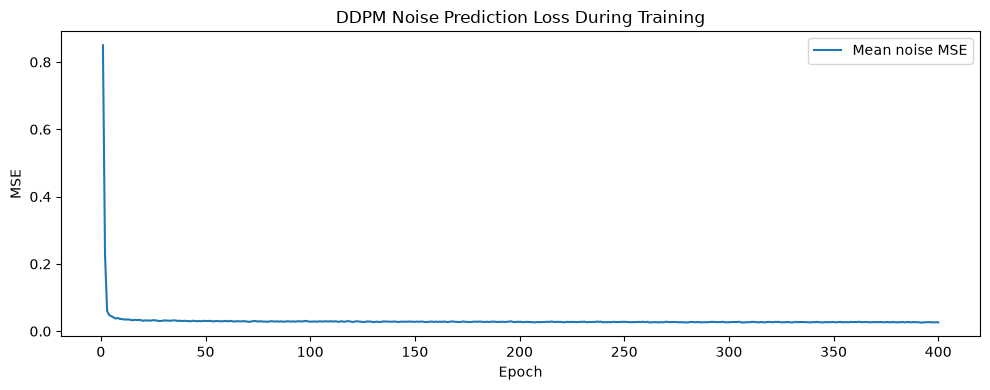

In [12]:
ema_weights_path = weights_dir / "DDPM_EMA_weights.pth"
torch.save({
    "ema_model": ema_model.state_dict(),
    "model_config": model_config, "diffusion_config": diffusion_config,
    "image_size": image_size, "global_step": global_step,
    "dataset_sha256": dataset_sha256,
}, ema_weights_path)
print("EMA weights saved to:", ema_weights_path)

plt.figure(figsize=(10, 4))
plt.title("DDPM Noise Prediction Loss During Training")
plt.plot([entry["epoch"] for entry in epoch_history],
         [entry["mse"] for entry in epoch_history], label="Mean noise MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "training_loss.png", dpi=150)
plt.show()


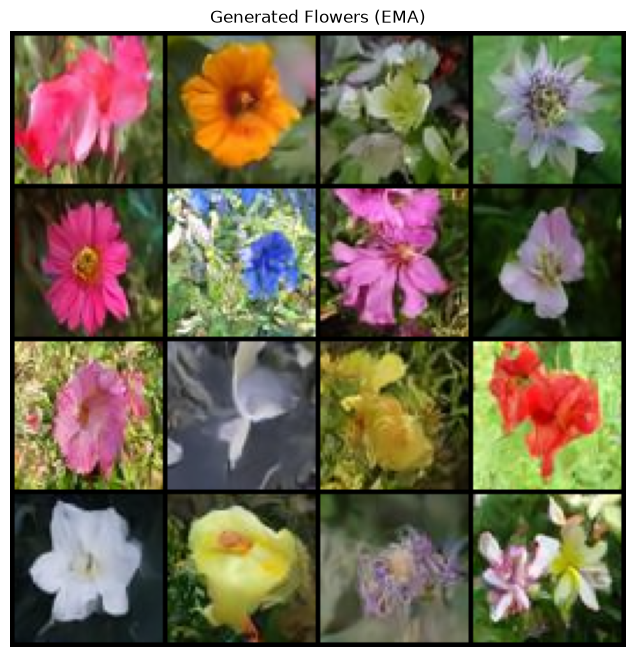

In [13]:
# Display the latest EMA preview. This small grid is not an evaluation dataset.
preview_rng = torch.Generator(device=device).manual_seed(manualSeed + 2000)
preview_images = diffusion.sample(
    ema_model, fixed_noise.shape, method="ddim", sampling_steps=preview_sampling_steps,
    eta=0.0, generator=preview_rng, initial_noise=fixed_noise, use_amp=amp_enabled,
).cpu()
plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Generated Flowers (EMA)")
plt.imshow(make_grid((preview_images + 1) / 2, nrow=4).permute(1, 2, 0).numpy())
plt.show()


## Create the generated dataset and submission ZIP
The export and archive-validation functions are supplied. They generate images
in small batches, write to a temporary ZIP and replace the final archive only
after all images pass validation. Do not collect all images on the GPU at once.

The default uses **DDPM-trained EMA weights with 250-step DDIM sampling**.
`sampling_method="ddpm"` uses all 1,000 DDPM steps. Record sampler, steps and
seed in your experiment table; comparison runs should control these settings.
Keep the announced image count, image size and filename contract for submission.
Running only the export cell again replaces the ZIP of this student variant.

In [14]:
def validate_submission_zip(path, expected_count, image_size=64):
    if expected_count < 1:
        raise ValueError("Expected image count must be positive.")
    expected_names = {"fake_%05d.png" % i for i in range(expected_count)}
    with zipfile.ZipFile(path, "r") as archive:
        names = archive.namelist()
        if len(names) != expected_count or len(set(names)) != expected_count:
            raise ValueError("Archive image count or duplicate filenames are invalid.")
        if set(names) != expected_names:
            raise ValueError("ZIP must contain only flat, sequential fake_XXXXX.png files.")
        for name in names:
            image_bytes = archive.read(name)
            if (image_bytes[:8] != b"\x89PNG\r\n\x1a\n"
                    or image_bytes[24:26] != b"\x08\x02"):
                raise ValueError("Expected an 8-bit RGB PNG: " + name)
            with Image.open(io.BytesIO(image_bytes)) as image:
                if image.format != "PNG" or image.mode != "RGB":
                    raise ValueError("Expected RGB PNG: " + name)
                if image.size != (image_size, image_size):
                    raise ValueError("Incorrect image size: " + name)
                image.load()
    return {"images": expected_count, "size": [image_size, image_size], "mode": "RGB"}

def export_submission(model, diffusion, path, count, image_size, batch_size,
                      method, sampling_steps, eta, seed, use_amp=False):
    if count < 1 or batch_size < 1:
        raise ValueError("Image count and batch size must be positive.")
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    rng = torch.Generator(device=diffusion.betas.device).manual_seed(seed)
    try:
        with zipfile.ZipFile(temporary, "w", compression=zipfile.ZIP_STORED) as archive:
            for start in tqdm(range(0, count, batch_size), desc="Generating submission batches"):
                current_batch = min(batch_size, count - start)
                generated = diffusion.sample(
                    model, (current_batch, 3, image_size, image_size), method=method,
                    sampling_steps=sampling_steps, eta=eta, generator=rng, use_amp=use_amp,
                )
                pixels = ((generated.float().cpu() + 1) * 127.5).round().clamp(0, 255)
                pixels = pixels.to(torch.uint8).permute(0, 2, 3, 1).numpy()
                for offset, pixel_array in enumerate(pixels):
                    image_bytes = io.BytesIO()
                    Image.fromarray(pixel_array, mode="RGB").save(image_bytes, format="PNG")
                    archive.writestr("fake_%05d.png" % (start + offset), image_bytes.getvalue())
                del generated, pixels
        summary = validate_submission_zip(temporary, count, image_size)
        os.replace(temporary, path)
        return summary
    except BaseException:
        temporary.unlink(missing_ok=True)
        raise


## Final output and submission
After completing the TODOs and training the model (or loading your trained
checkpoint), execute the next cell. It creates
**`student_outputs/DDPM/images.zip`** and saves generation settings
separately in `student_outputs/DDPM/outputs/generation_config.json`.

The export cell automatically validates every generated image before
finalizing the ZIP. You do not need to run an external validation program.
Choose your best ZIP from the U-Net or DiT version and submit that one file
to Kaggle. FID scoring is separate from the built-in format checks and is
not calculated by this notebook.


In [15]:
from tqdm import tqdm
generation_start = time.perf_counter()
archive_summary = export_submission(
    ema_model, diffusion, submission_path, num_submission_images, image_size,
    sample_batch_size, sampling_method, sampling_steps, ddim_eta, submission_seed,
    use_amp=amp_enabled,
)
generation_config = {
    "archive": submission_path.name,
    "archive_sha256": hashlib.sha256(submission_path.read_bytes()).hexdigest(),
    "archive_format": "flat sequential fake_XXXXX.png; 8-bit RGB PNG",
    "num_images": num_submission_images, "image_size": image_size,
    "sampler": sampling_method,
    "sampling_steps": diffusion_steps if sampling_method == "ddpm" else sampling_steps,
    "ddim_eta": ddim_eta, "seed": submission_seed,
    "sample_batch_size": sample_batch_size, "use_amp": amp_enabled,
    "model_config": model_config, "diffusion_config": diffusion_config,
    "global_step": global_step, "dataset_sha256": dataset_sha256,
    "ema_weights_sha256": hashlib.sha256(ema_weights_path.read_bytes()).hexdigest(),
    "torch_version": torch.__version__, "device": str(device),
    "seconds": time.perf_counter() - generation_start,
}
(output_dir / "generation_config.json").write_text(
    json.dumps(generation_config, indent=2), encoding="utf-8")
print("Validated submission:", archive_summary)
print("Final ZIP:", submission_path)
print("Archive size: %.2f MiB" % (submission_path.stat().st_size / 2**20))
print("Generation time: %.1f seconds" % generation_config["seconds"])
display(FileLink(os.path.relpath(submission_path, Path.cwd())))


Generating submission batches: 100%|██████████| 256/256 [20:06<00:00,  4.71s/it]


Validated submission: {'images': 8189, 'size': [64, 64], 'mode': 'RGB'}
Final ZIP: /root/DL/HW6/student_outputs/DDPM/images.zip
Archive size: 67.85 MiB
Generation time: 1209.7 seconds


/root/DL/HW6/student_outputs/DDPM/images.zip